# Feature engineering

Load the final rental dataset with all proximity features and explore
`weekly_rent`.

### Imports

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

### Read the Rental Dataset in

In [ ]:
FINAL_RENTALS_PATH = "../rea_data/analysis/rental_data_merged_final/\
    rentals_final.parquet"

rentals = pd.read_parquet(FINAL_RENTALS_PATH)
print(rentals.shape)
rentals.head()

(12316, 120)


,lat,lon,listing_id,suburb,weekly_rent,date_listed,bedrooms,bathrooms,carspaces,property_type,...,bus_stops_PTV_road_distance_m,bus_stops_PTV_duration_s,bus_stops_PTV_is_confirmed,nearest_beaches_facility_id,beaches_road_distance_m,beaches_duration_s,beaches_is_confirmed,crime_rate,median_weekly_income,population
0,-37.830982,144.87091,16782629,SOUTH KINGSVILLE,460.0,2025-08-13,2.0,1.0,2.0,Apartment / Unit / Flat,...,80.01,19.20,True,BEACH_way_34620304,6052.53,647.84,True,7959.260566,1598.0,20328.0
1,-37.826218,144.86755,17471867,SOUTH KINGSVILLE,400.0,2025-03-06,2.0,1.0,1.0,Apartment / Unit / Flat,...,448.33,56.64,True,BEACH_way_712654263,6667.64,724.43,True,8166.462265,1598.0,20328.0
2,-37.831226,144.86632,17721851,SOUTH KINGSVILLE,795.0,2025-08-19,3.0,2.0,3.0,Townhouse,...,222.06,45.64,True,BEACH_way_712654263,6162.61,676.87,True,7959.260566,1078.0,16493.0
3,-37.827423,144.86768,17725855,SOUTH KINGSVILLE,675.0,2025-08-21,3.0,1.0,2.0,Townhouse,...,164.95,17.65,True,BEACH_way_712654263,6622.66,717.06,True,7959.260566,1598.0,20328.0
4,-37.826270,144.86790,17745057,SOUTH KINGSVILLE,450.0,2025-09-03,2.0,1.0,0.0,Apartment / Unit / Flat,...,366.99,40.18,True,BEACH_way_712654263,6824.72,739.59,True,7959.260566,1598.0,20328.0


## Distribution of weekly rent

In [40]:
print(rentals["weekly_rent"].describe())
print(f"\nNulls: {rentals['weekly_rent'].isna().sum()}")

count    12316.000000
mean       630.914907
std        294.480402
min        205.000000
25%        490.000000
50%        565.000000
75%        690.000000
max      10000.000000
Name: weekly_rent, dtype: float64

Nulls: 0


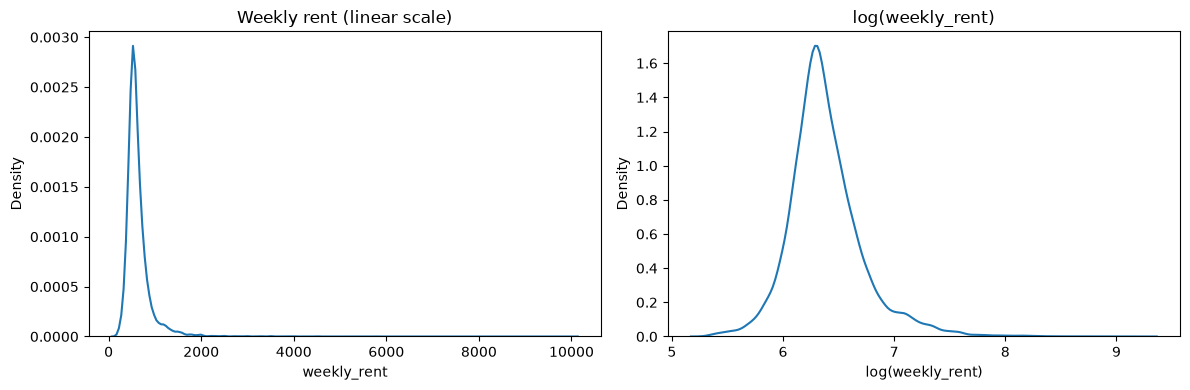

In [41]:
log_rent = np.log(rentals["weekly_rent"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(rentals["weekly_rent"], ax=axes[0])
axes[0].set_title("Weekly rent (linear scale)")

sns.kdeplot(log_rent, ax=axes[1])
axes[1].set_xlabel("log(weekly_rent)")
axes[1].set_title("log(weekly_rent)")

plt.tight_layout()
plt.show()

## Distribution of all numerical features (raw vs log)

For every numeric column with more than 2 unique values (so 0/1 flags are
excluded — those are categorical, not continuous), plot the raw distribution
next to its `log1p` transform, and compare skewness. Heavily skewed raw
features that become noticeably less skewed after log-transforming are good
candidates to log before feeding into the Lasso model.

In [42]:
# Numeric columns with more than 2 unique values (excludes 0/1 categorical flags)
numeric_cols = rentals.select_dtypes(include=[np.number]).columns
candidate_cols = [
    col for col in numeric_cols if rentals[col].nunique(dropna=True) > 2
]
candidate_cols = [col for col in candidate_cols if col != "weekly_rent"]

print(f"{len(candidate_cols)} numeric columns with >2 unique values:")
print(candidate_cols)

40 numeric columns with >2 unique values:
['lat', 'lon', 'bedrooms', 'bathrooms', 'carspaces', 'listed_year', 'listed_month', 'dist_to_cbd_km_driving', 'sports_rec_road_distance_m', 'sports_rec_duration_s', 'shopping_centre_road_distance_m', 'shopping_centre_duration_s', 'medical_doctors_road_distance_m', 'medical_doctors_duration_s', 'medical_clinic_road_distance_m', 'medical_clinic_duration_s', 'hospital_road_distance_m', 'hospital_duration_s', 'park_reserve_road_distance_m', 'park_reserve_duration_s', 'park_national_road_distance_m', 'park_national_duration_s', 'park_local_road_distance_m', 'park_local_duration_s', 'nearest_school_primary_facility_id', 'school_primary_road_distance_m', 'school_primary_duration_s', 'nearest_school_secondary_facility_id', 'school_secondary_road_distance_m', 'school_secondary_duration_s', 'train_stations_PTV_road_distance_m', 'train_stations_PTV_duration_s', 'nearest_bus_stops_PTV_facility_id', 'bus_stops_PTV_road_distance_m', 'bus_stops_PTV_duration_s

### Raw vs. log1p KDE plots

`log1p` (not plain `log`) is used since some proximity/distance features can
be exactly 0 (e.g. a property directly adjacent to a park), and `log1p`
handles that safely where `log` would break. Any column with negative values
is shifted to be positive first, since a log transform can't handle negatives
directly.

,column,raw_skew,log_skew
0,lat,3.613602,2.313464
1,lon,-0.307839,-0.387834
2,bedrooms,5.467879,-0.677572
3,bathrooms,1.703554,0.387274
4,carspaces,3.901712,-0.449434
5,listed_year,-13.438271,-13.453271
6,listed_month,-1.965467,-3.600937
7,dist_to_cbd_km_driving,3.214667,0.157759
8,sports_rec_road_distance_m,7.667081,-0.353400
9,sports_rec_duration_s,2.855861,-0.699229




In [43]:
n_cols = len(candidate_cols)
fig, axes = plt.subplots(n_cols, 2, figsize=(12, 3.2 * n_cols))

# Keep 2D indexing working even if there's only one candidate column
if n_cols == 1:
    axes = axes.reshape(1, 2)

skew_summary = []

for i, col in enumerate(candidate_cols):
    data = rentals[col].dropna()

    sns.kdeplot(data, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} (raw)")

    if (data < 0).any():
        shifted = data - data.min() + 1
        log_data = np.log1p(shifted)
        log_label = f"log1p({col}, shifted positive)"
    else:
        log_data = np.log1p(data)
        log_label = f"log1p({col})"

    sns.kdeplot(log_data, ax=axes[i, 1])
    axes[i, 1].set_title(log_label)

    skew_summary.append(
        {"column": col, "raw_skew": data.skew(), "log_skew": log_data.skew()}
    )

plt.tight_layout()
#plt.show()

skew_df = pd.DataFrame(skew_summary)
skew_df

### Log-transform distance/scale features

Apply `log1p` to every column ending in `_m` (metres) or `_s` (seconds), excluding any column starting with `park_reserve` (log transform not required). Original columns are kept; logged versions are
added as new `log_<col>` columns so both are available downstream.

In [44]:
log_target_cols = [
    col
    for col in rentals.columns
    if (col.endswith("_m") or col.endswith("_s"))
    and not col.startswith("park_reserve")
]

print(f"Logging {len(log_target_cols)} columns:")
print(log_target_cols)

for col in log_target_cols:
    rentals[f"log_{col}"] = np.log1p(rentals[col])

Logging 24 columns:
['sports_rec_road_distance_m', 'sports_rec_duration_s', 'shopping_centre_road_distance_m', 'shopping_centre_duration_s', 'medical_doctors_road_distance_m', 'medical_doctors_duration_s', 'medical_clinic_road_distance_m', 'medical_clinic_duration_s', 'hospital_road_distance_m', 'hospital_duration_s', 'park_national_road_distance_m', 'park_national_duration_s', 'park_local_road_distance_m', 'park_local_duration_s', 'school_primary_road_distance_m', 'school_primary_duration_s', 'school_secondary_road_distance_m', 'school_secondary_duration_s', 'train_stations_PTV_road_distance_m', 'train_stations_PTV_duration_s', 'bus_stops_PTV_road_distance_m', 'bus_stops_PTV_duration_s', 'beaches_road_distance_m', 'beaches_duration_s']


### Log-transform remaining count features

`bedrooms`, `bathrooms`, `carspaces`, and `dist_to_cbd_km_driving` don't match
the `_m`/`_s` suffix pattern above but are still worth log-transforming for
the same reason (right-skewed counts and distances). We also log the crime rate. 
Add these to the same logging step, then confirm the full set of columns now
 in the dataframe.

In [47]:
extra_log_cols = ["bedrooms", "bathrooms", "carspaces", 
                  "dist_to_cbd_km_driving"]

for col in extra_log_cols:
    rentals[f"log_{col}"] = np.log1p(rentals[col])

rentals["log_crime_rate"] = np.log1p(rentals["crime_rate"])

print(rentals.columns.tolist())

['lat', 'lon', 'listing_id', 'suburb', 'weekly_rent', 'date_listed', 'bedrooms', 'bathrooms', 'carspaces', 'property_type', 'feat_built_in_wardrobes', 'feat_heating', 'feat_dishwasher', 'feat_secure_parking', 'feat_internal_laundry', 'feat_air_conditioning', 'feat_balcony___deck', 'feat_gas', 'feat_floorboards', 'feat_bath', 'feat_intercom', 'feat_ensuite', 'feat_fully_fenced', 'feat_study', 'feat_furnished', 'feat_split_system_air_conditioning', 'feat_pets_allowed', 'feat_close_to_shops', 'feat_split_system_heating', 'feat_close_to_transport', 'feat_close_to_schools', 'feat_remote_garage', 'feat_shed', 'feat_ducted_heating', 'feat_garden___courtyard', 'feat_gym', 'feat_outdoor_entertainment_area', 'feat_balcony', 'feat_broadband_internet_access', 'feat_alarm_system', 'feat_swimming_pool', 'feat_courtyard', 'feat_solar_panels', 'feat_fireplaces', 'feat_pool_spa_count_0', 'feat_bathtub', 'feat_ensuites', 'feat_carpeted', 'feat_gas_appliances', 'feat_evaporative_cooling', 'feat_openable_

### Drop irrelevant features (id, is_confirmed flags)

In [ ]:
# Identify columns to drop: any column containing "_id" or "is_confirmed" in 
#  its name, as these are identifiers/flags irrelevant to the modeling task.
columns_to_drop = [
    column_name
    for column_name in rentals.columns
    if (("_id" in column_name or "is_confirmed" in column_name)
    and column_name != "listing_id")
]
print(len(columns_to_drop))
print(columns_to_drop)

# Drop the identified columns, keeping only relevant features.
rentals = rentals.drop(columns=columns_to_drop)

26
['nearest_sports_rec_facility_id', 'sports_rec_is_confirmed', 'nearest_shopping_centre_facility_id', 'shopping_centre_is_confirmed', 'nearest_medical_doctors_facility_id', 'medical_doctors_is_confirmed', 'nearest_medical_clinic_facility_id', 'medical_clinic_is_confirmed', 'nearest_hospital_facility_id', 'hospital_is_confirmed', 'nearest_park_reserve_facility_id', 'park_reserve_is_confirmed', 'nearest_park_national_facility_id', 'park_national_is_confirmed', 'nearest_park_local_facility_id', 'park_local_is_confirmed', 'nearest_school_primary_facility_id', 'school_primary_is_confirmed', 'nearest_school_secondary_facility_id', 'school_secondary_is_confirmed', 'nearest_train_stations_PTV_facility_id', 'train_stations_PTV_is_confirmed', 'nearest_bus_stops_PTV_facility_id', 'bus_stops_PTV_is_confirmed', 'nearest_beaches_facility_id', 'beaches_is_confirmed']


### Relationship between features and weekly rent

Visualise each numeric feature (>2 unique values) against `weekly_rent`. Where a logged version of a feature exists, plot that instead of the raw version — no need to look at both.



In [53]:
excluded_cols = {"weekly_rent"}

base_candidate_cols = [
    col
    for col in rentals.select_dtypes(include=[np.number]).columns
    if not col.startswith("log_")
    and col not in excluded_cols
    and rentals[col].nunique(dropna=True) > 2
]

plot_cols = [
    f"log_{col}" if f"log_{col}" in rentals.columns else col
    for col in base_candidate_cols
]

log_rent = np.log1p(rentals["weekly_rent"])

n_cols = len(plot_cols)
fig, axes = plt.subplots(n_cols, 1, figsize=(5, 3.2 * n_cols))

if n_cols == 1:
    axes = [axes]

for i, col in enumerate(plot_cols):
    axes[i].scatter(rentals[col], log_rent, alpha=0.2, s=8)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("log_weekly_rent")

plt.tight_layout()
plt.show()

### Drop the non-log version if logged version exists

In [ ]:
# Drop raw (non-log) columns whenever a corresponding log_ version exists in 
# the df, since the log-transformed version is the one used for modeling.
columns_to_drop = [
    column_name
    for column_name in rentals.columns
    if f"log_{column_name}" in rentals.columns
]
print(columns_to_drop)
print(len(columns_to_drop))

rentals = rentals.drop(columns=columns_to_drop)

['bedrooms', 'bathrooms', 'carspaces', 'dist_to_cbd_km_driving', 'sports_rec_road_distance_m', 'sports_rec_duration_s', 'shopping_centre_road_distance_m', 'shopping_centre_duration_s', 'medical_doctors_road_distance_m', 'medical_doctors_duration_s', 'medical_clinic_road_distance_m', 'medical_clinic_duration_s', 'hospital_road_distance_m', 'hospital_duration_s', 'park_national_road_distance_m', 'park_national_duration_s', 'park_local_road_distance_m', 'park_local_duration_s', 'school_primary_road_distance_m', 'school_primary_duration_s', 'school_secondary_road_distance_m', 'school_secondary_duration_s', 'train_stations_PTV_road_distance_m', 'train_stations_PTV_duration_s', 'bus_stops_PTV_road_distance_m', 'bus_stops_PTV_duration_s', 'beaches_road_distance_m', 'beaches_duration_s', 'crime_rate']
29


### Multicollinearity check

### Distance vs. duration correlation, per destination type

For each destination type that has both a `_road_distance_m` and a
`_duration_s` feature (e.g. medical doctors, train stations), check how
correlated the pair actually is. High correlation confirms they're
largely redundant — a strong candidate to drop one of the two rather than
feed both into the model.

In [ ]:
distance_cols = [col for col in rentals.columns if col.endswith(
    "_road_distance_m")]

pair_correlations = []

for dist_col in distance_cols:
    base_name = dist_col.replace("_road_distance_m", "")
    duration_col = f"{base_name}_duration_s"

    if duration_col in rentals.columns:
        corr = rentals[dist_col].corr(rentals[duration_col])
        pair_correlations.append({
            "destination_type": base_name,
            "distance_col": dist_col,
            "duration_col": duration_col,
            "correlation": corr,
        })

pair_corr_df = pd.DataFrame(pair_correlations).sort_values(
    "correlation", ascending=False
)
pair_corr_df

,destination_type,distance_col,duration_col,correlation
10,log_train_stations_PTV,log_train_stations_PTV_road_distance_m,log_train_stations_PTV_duration_s,0.978681
3,log_medical_doctors,log_medical_doctors_road_distance_m,log_medical_doctors_duration_s,0.975074
4,log_medical_clinic,log_medical_clinic_road_distance_m,log_medical_clinic_duration_s,0.973547
12,log_beaches,log_beaches_road_distance_m,log_beaches_duration_s,0.972976
5,log_hospital,log_hospital_road_distance_m,log_hospital_duration_s,0.972731
2,log_shopping_centre,log_shopping_centre_road_distance_m,log_shopping_centre_duration_s,0.971510
9,log_school_secondary,log_school_secondary_road_distance_m,log_school_secondary_duration_s,0.954208
11,log_bus_stops_PTV,log_bus_stops_PTV_road_distance_m,log_bus_stops_PTV_duration_s,0.949508
6,log_park_national,log_park_national_road_distance_m,log_park_national_duration_s,0.945650
1,log_sports_rec,log_sports_rec_road_distance_m,log_sports_rec_duration_s,0.943151


### Drop all duration features

Distance and duration are near-perfectly correlated for every destination
type (confirmed above), and were driving the highest VIF scores. Keep
`_road_distance_m` as the primary proximity measure and drop every
`_duration_s` column, rather than deciding feature-by-feature.

In [57]:
duration_cols = [col for col in rentals.columns if col.endswith("_duration_s")]

print(f"Dropping {len(duration_cols)} duration columns:")
print(duration_cols)

rentals = rentals.drop(columns=duration_cols)

Dropping 13 duration columns:
['park_reserve_duration_s', 'log_sports_rec_duration_s', 'log_shopping_centre_duration_s', 'log_medical_doctors_duration_s', 'log_medical_clinic_duration_s', 'log_hospital_duration_s', 'log_park_national_duration_s', 'log_park_local_duration_s', 'log_school_primary_duration_s', 'log_school_secondary_duration_s', 'log_train_stations_PTV_duration_s', 'log_bus_stops_PTV_duration_s', 'log_beaches_duration_s']


In [59]:
exclude_from_check = {"weekly_rent", "log_weekly_rent"}

model_features = [
    col
    for col in rentals.select_dtypes(include=[np.number]).columns
    if col not in exclude_from_check
    and f"log_{col}" not in rentals.columns
]

print(f"{len(model_features)} features going into the VIF check:")
print(model_features)

76 features going into the VIF check:
['lat', 'lon', 'feat_built_in_wardrobes', 'feat_heating', 'feat_dishwasher', 'feat_secure_parking', 'feat_internal_laundry', 'feat_air_conditioning', 'feat_balcony___deck', 'feat_gas', 'feat_floorboards', 'feat_bath', 'feat_intercom', 'feat_ensuite', 'feat_fully_fenced', 'feat_study', 'feat_furnished', 'feat_split_system_air_conditioning', 'feat_pets_allowed', 'feat_close_to_shops', 'feat_split_system_heating', 'feat_close_to_transport', 'feat_close_to_schools', 'feat_remote_garage', 'feat_shed', 'feat_ducted_heating', 'feat_garden___courtyard', 'feat_gym', 'feat_outdoor_entertainment_area', 'feat_balcony', 'feat_broadband_internet_access', 'feat_alarm_system', 'feat_swimming_pool', 'feat_courtyard', 'feat_solar_panels', 'feat_fireplaces', 'feat_pool_spa_count_0', 'feat_bathtub', 'feat_ensuites', 'feat_carpeted', 'feat_gas_appliances', 'feat_evaporative_cooling', 'feat_openable_windows', 'feat_broadband', 'feat_rumpus_room', 'feat_ducted_cooling', 

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Drop the redundant, exactly-collinear feature (centered version replaces it)
vif_features = [f for f in model_features if f != "log_carspaces"]

vif_data = rentals[vif_features].dropna()
vif_data = sm.add_constant(vif_data)  # required for correct VIFs

vif_df = pd.DataFrame({
    "feature": vif_data.columns,
    "VIF": [
        variance_inflation_factor(vif_data.values, i)
        for i in range(vif_data.shape[1])
    ],
})
vif_df = vif_df[vif_df["feature"] != "const"] 
# drop the intercept row from display

with pd.option_context("display.max_rows", None):
    display(vif_df.sort_values("VIF", ascending=False))

,feature,VIF
20,feat_close_to_shops,10.061428
22,feat_close_to_transport,7.665053
23,feat_close_to_schools,7.265064
74,log_dist_to_cbd_km_driving,3.980893
21,feat_split_system_heating,2.685984
18,feat_split_system_air_conditioning,2.599360
58,median_weekly_income,2.322442
72,log_bedrooms,2.272342
62,log_medical_doctors_road_distance_m,2.231049
63,log_medical_clinic_road_distance_m,2.217106


### Drop redundant "close to X" flags

`feat_close_to_shops`, `feat_close_to_transport`, and `feat_close_to_schools`
have the highest remaining VIF (10.3, 8.0, 7.4) — likely because they're
proxying the same information already captured more precisely by the actual
`log_*_road_distance_m` features for those same categories. Drop the flags
and keep the continuous distance measures.

In [61]:
cols_to_drop = [
    "feat_close_to_shops",
    "feat_close_to_transport",
    "feat_close_to_schools",
]

rentals = rentals.drop(columns=cols_to_drop)
print(f"Dropped: {cols_to_drop}")

Dropped: ['feat_close_to_shops', 'feat_close_to_transport', 'feat_close_to_schools']


### Correlation Heatmap of Numerical Features

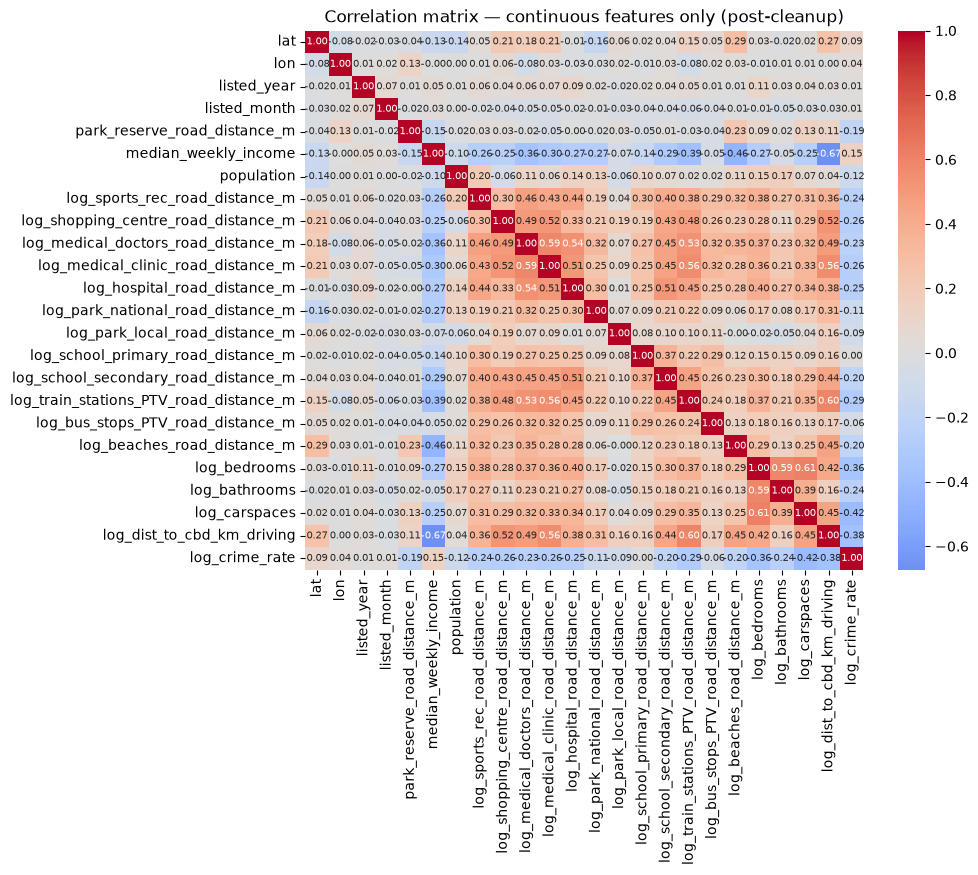

In [63]:
model_features = [col for col in model_features if col in rentals.columns]

binary_cols = [
    col for col in model_features if rentals[col].nunique(dropna=True) == 2
]
continuous_cols = [col for col in model_features if col not in binary_cols]

corr_matrix_continuous = rentals[continuous_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix_continuous,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
)
plt.title("Correlation matrix — continuous features only (post-cleanup)")
plt.show()

### Export to Parquet file in Development Layer

In [ ]:
from pathlib import Path

DEV_LAYER_PATH = Path("../rea_data/analysis/rental_data_development/\
                      rentals.parquet")
DEV_LAYER_PATH.parent.mkdir(parents=True, exist_ok=True)

rentals.to_parquet(DEV_LAYER_PATH, index=False)
print(f"Exported {rentals.shape[0]} rows, {rentals.shape[1]}\
      columns to {DEV_LAYER_PATH}")

Exported 12316 rows, 78 columns to ../rea_data/analysis/rental_data_development/rentals.parquet
